### 0. 데이터 불러오기

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kashishparmar02/social-media-sentiments-analysis-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\82102\.cache\kagglehub\datasets\kashishparmar02\social-media-sentiments-analysis-dataset\versions\3


In [5]:
import os

# 다운로드된 폴더 안 파일 목록 확인
for f in os.listdir(path):
    print(f)


sentimentdataset.csv


In [6]:
import pandas as pd

file_name = "sentimentdataset.csv"
df = pd.read_csv(os.path.join(path, file_name))

df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [7]:
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [8]:
df.columns

Index(['Text', 'Sentiment', 'Timestamp', 'User', 'Platform', 'Hashtags',
       'Retweets', 'Likes', 'Country', 'Year', 'Month', 'Day', 'Hour'],
      dtype='str')

##### 전처리 - 공백 제거

In [9]:
# ── 1) 공백 문제 실제 확인 ────────────────────────────────────────
print("=== 공백 제거 전 샘플 ===")
print(df['Sentiment'].head(5).apply(repr))

# ── 2) strip()으로 앞뒤 공백 제거 ──────────────────────────────────
df['Sentiment'] = df['Sentiment'].astype(str).str.strip()

print("\n=== 공백 제거 후 샘플 ===")
print(df['Sentiment'].head(5).apply(repr))

# ── 3) 제거 후 고유 레이블 개수 재확인 (혹시 중복 병합되며 줄었는지) ──
print("\n=== 공백 제거 후 고유 레이블 개수 ===")
print(df['Sentiment'].nunique())

=== 공백 제거 전 샘플 ===
0    ' Positive  '
1    ' Negative  '
2    ' Positive  '
3    ' Positive  '
4    ' Neutral   '
Name: Sentiment, dtype: str

=== 공백 제거 후 샘플 ===
0    'Positive'
1    'Negative'
2    'Positive'
3    'Positive'
4     'Neutral'
Name: Sentiment, dtype: str

=== 공백 제거 후 고유 레이블 개수 ===
191


In [10]:
df['Text'] = df['Text'].astype(str).str.strip()
df['User'] = df['User'].astype(str).str.strip()
df['Platform'] = df['Platform'].astype(str).str.strip()
df['Hashtags'] = df['Hashtags'].astype(str).str.strip()
df['Country'] = df['Country'].astype(str).str.strip()
df['Sentiment'] = df['Sentiment'].astype(str).str.strip()

### 1. 감성 레이블 재매핑

##### 1_1. 테스트 

In [11]:
import os

In [12]:
# ── 1) 현재 작업 디렉토리 확인 (기본적으로 이 위치에 저장하면 됨) ──
print("=== 1) 현재 작업 디렉토리 (cwd) ===")
print(os.getcwd())

# ── 2) INPUT_DIR 환경변수 확인 (업로드 파일 전용 폴더가 있는 경우) ──
input_dir = os.environ.get('INPUT_DIR')
print("\n=== 2) INPUT_DIR 환경변수 ===")
if input_dir:
    print("INPUT_DIR 경로:", input_dir)
else:
    print("INPUT_DIR 환경변수 없음 → 현재 작업 디렉토리 사용 권장")

# ── 3) 두 경로 모두 실제 쓰기 권한이 있는지 확인 ───────────────
candidate_dirs = [os.getcwd()]
if input_dir:
    candidate_dirs.append(input_dir)

print("\n=== 3) 후보 경로별 쓰기 권한 확인 ===")
for d in candidate_dirs:
    writable = os.access(d, os.W_OK)
    print(f"{d} → 쓰기 가능: {writable}")

# ── 4) 최종 저장 권장 경로 및 전체 파일 경로 출력 ──────────────
target_dir = input_dir if input_dir and os.access(input_dir, os.W_OK) else os.getcwd()
target_path = os.path.join(target_dir, 'NRC-emotion-lexicon-wordlevel-alphabetized-v0.92.txt')

print("\n=== 4) 파일 저장 권장 경로 ===")
print(target_path)

=== 1) 현재 작업 디렉토리 (cwd) ===
c:\Users\82102\Desktop\study\study

=== 2) INPUT_DIR 환경변수 ===
INPUT_DIR 환경변수 없음 → 현재 작업 디렉토리 사용 권장

=== 3) 후보 경로별 쓰기 권한 확인 ===
c:\Users\82102\Desktop\study\study → 쓰기 가능: True

=== 4) 파일 저장 권장 경로 ===
c:\Users\82102\Desktop\study\study\NRC-emotion-lexicon-wordlevel-alphabetized-v0.92.txt


In [13]:
from nrclex import NRCLex

In [14]:
# ── 1) 내장 lexicon 딕셔너리 추출 ─────────────────────────────────
sample = NRCLex('dummy')
nrc_lexicon = sample.__lexicon__

print("=== 1) 내장 lexicon 총 단어 수 ===")
print(len(nrc_lexicon))

# ── 2) 핵심 감정 단어 검증 ─────────────────────────────────────────
print("\n=== 2) 핵심 감정 단어 매핑 확인 ===")
for w in ['happy', 'anger', 'joy', 'sad', 'fear', 'amusement', 'disgust']:
    print(f"{w:12s} : {nrc_lexicon.get(w, '❌ 사전에 없음')}")

# ── 3) 카테고리 종류 전체 확인 (positive/negative 포함 여부) ────────
all_categories = set()
for cats in nrc_lexicon.values():
    all_categories.update(cats)
print("\n=== 3) 전체 카테고리 목록 ===")
print(sorted(all_categories))

=== 1) 내장 lexicon 총 단어 수 ===
6468

=== 2) 핵심 감정 단어 매핑 확인 ===
happy        : ['anticipation', 'joy', 'positive', 'trust']
anger        : ['anger', 'negative']
joy          : ['joy', 'positive']
sad          : ❌ 사전에 없음
fear         : ['anger', 'fear', 'negative']
amusement    : ['joy', 'positive']
disgust      : ['anger', 'disgust', 'fear', 'negative', 'sadness']

=== 3) 전체 카테고리 목록 ===
['anger', 'anticipation', 'disgust', 'fear', 'joy', 'negative', 'positive', 'sadness', 'surprise', 'trust']


##### 1_2. Lexicon 내장 딕셔너리 직접 추출

In [15]:
from nrclex import NRCLex
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import sentiwordnet as swn

nltk.download('wordnet')
nltk.download('sentiwordnet')
nltk.download('omw-1.4')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package sentiwordnet to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package sentiwordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [16]:
# ── 1) 내장 NRC Lexicon 딕셔너리 추출 ───────────────────────────
_dummy = NRCLex('dummy')
nrc_lexicon = _dummy.__lexicon__

print("=== 1) NRC Lexicon 로드 결과 ===")
print("총 단어 수:", len(nrc_lexicon))

all_categories = set()
for cats in nrc_lexicon.values():
    all_categories.update(cats)
print("전체 카테고리 (10개):", sorted(all_categories))

# ── 2) 감정 카테고리 → 극성 매핑 테이블 ──────────────────────────
# positive/negative 태그가 직접 없는 단어(예: 'surprise'만 태깅된 경우)를 위한 보조 규칙
emotion_polarity_fallback = {
    'joy': 'positive', 'trust': 'positive', 'anticipation': 'positive',
    'anger': 'negative', 'disgust': 'negative', 'fear': 'negative', 'sadness': 'negative',
    'surprise': None  # 극성이 명확하지 않아 판단 보류
}

=== 1) NRC Lexicon 로드 결과 ===
총 단어 수: 6468
전체 카테고리 (10개): ['anger', 'anticipation', 'disgust', 'fear', 'joy', 'negative', 'positive', 'sadness', 'surprise', 'trust']


##### 1_3. CamelCase 분리 + 극성 스코어 함수

In [17]:
# ── 1) CamelCase 복합어 분리 함수 ─────────────────────────────────
def split_camel_case(label):
    tokens = re.findall(r'[A-Z][a-z]*|[a-z]+', label)
    return tokens if tokens else [label]

# ── 2) NRC 내장 딕셔너리 기반 극성 스코어 함수 ────────────────────
def get_nrc_polarity(label, lex_dict):
    tokens = split_camel_case(label)
    pos_score, neg_score = 0, 0
    matched_tokens = []
    for token in tokens:
        cats = lex_dict.get(token.lower())
        if not cats:
            continue
        matched_tokens.append(token.lower())

        if 'positive' in cats:
            pos_score += 1
        if 'negative' in cats:
            neg_score += 1

        # positive/negative 직접 태그가 없는 경우 → 감정 카테고리로 보조 판단
        if 'positive' not in cats and 'negative' not in cats:
            for cat in cats:
                fb = emotion_polarity_fallback.get(cat)
                if fb == 'positive':
                    pos_score += 1
                elif fb == 'negative':
                    neg_score += 1
    return pos_score, neg_score, matched_tokens

# ── 3) SentiWordNet 보조 스코어 함수 (NRC 완전 미탐지 단어 전용) ────
def get_sentiwordnet_polarity(label):
    tokens = split_camel_case(label)
    pos_score, neg_score = 0, 0
    for token in tokens:
        synsets = list(swn.senti_synsets(token.lower()))[:3]
        if synsets:
            pos_score += np.mean([s.pos_score() for s in synsets])
            neg_score += np.mean([s.neg_score() for s in synsets])
    return pos_score, neg_score

#### 1_4. 레이블별 극성 스코어 산출 및 1차 자동 매핑

In [18]:
unique_labels = df['Sentiment'].unique()
print("=== 1) 원본 고유 감정 레이블 개수 ===")
print(len(unique_labels))

label_polarity = []
for label in unique_labels:
    nrc_pos, nrc_neg, matched = get_nrc_polarity(label, nrc_lexicon)

    # NRC에서 전혀 매칭이 안 된 경우에만 SentiWordNet을 보조로 사용
    if len(matched) == 0:
        swn_pos, swn_neg = get_sentiwordnet_polarity(label)
        source = 'SentiWordNet(fallback)'
        total_pos, total_neg = swn_pos, swn_neg
    else:
        source = 'NRC'
        total_pos, total_neg = nrc_pos, nrc_neg

    if total_pos == 0 and total_neg == 0:
        mapped = 'Neutral'          # 두 사전 모두 미탐지 → 수동검토 대상
    elif total_pos > total_neg:
        mapped = 'Positive'
    elif total_neg > total_pos:
        mapped = 'Negative'
    else:
        mapped = 'Neutral'          # 동점 → 수동검토 권장

    label_polarity.append({
        'label': label,
        'source': source,
        'pos_score': round(total_pos, 3),
        'neg_score': round(total_neg, 3),
        'matched_tokens': matched,
        'mapped_grouped': mapped
    })

polarity_df = pd.DataFrame(label_polarity)

print("\n=== 2) 레이블별 극성 스코어 및 1차 매핑 결과 (상위 20개) ===")
display(polarity_df.head(20))

print("\n=== 3) 매핑 근거 소스 비중 ===")
display(polarity_df['source'].value_counts().to_frame('count'))

manual_review = polarity_df[
    (polarity_df['pos_score'] == 0) & (polarity_df['neg_score'] == 0)
]
print(f"\n=== 4) 수동 검토 필요 레이블 : {len(manual_review)}건 ===")
display(manual_review[['label']])

# ── 5) 핵심 감정 단어 재검증 (오류 재발 방지 체크) ─────────────────
print("\n=== 5) 핵심 감정 레이블 매핑 재검증 ===")
sanity_check = ['Anger', 'Amusement', 'Disgust', 'Joy', 'Sadness', 'Happiness']
display(polarity_df[polarity_df['label'].isin(sanity_check)])

=== 1) 원본 고유 감정 레이블 개수 ===
191

=== 2) 레이블별 극성 스코어 및 1차 매핑 결과 (상위 20개) ===


,label,source,pos_score,neg_score,matched_tokens,mapped_grouped
0,Positive,SentiWordNet(fallback),0.208,0.000,[],Positive
1,Negative,NRC,0.000,1.000,[negative],Negative
2,Neutral,NRC,2.000,0.000,[neutral],Positive
3,Anger,NRC,0.000,1.000,[anger],Negative
4,Fear,NRC,0.000,1.000,[fear],Negative
5,Sadness,NRC,0.000,1.000,[sadness],Negative
6,Disgust,NRC,0.000,1.000,[disgust],Negative
7,Happiness,NRC,1.000,0.000,[happiness],Positive
8,Joy,NRC,1.000,0.000,[joy],Positive
9,Love,NRC,1.000,0.000,[love],Positive



=== 3) 매핑 근거 소스 비중 ===


,count
source,
NRC,129
SentiWordNet(fallback),62



=== 4) 수동 검토 필요 레이블 : 5건 ===


,label
33,Empowerment
117,Resilience
136,Solitude
155,Iconic
157,Engagement



=== 5) 핵심 감정 레이블 매핑 재검증 ===


,label,source,pos_score,neg_score,matched_tokens,mapped_grouped
3,Anger,NRC,0.0,1.0,[anger],Negative
5,Sadness,NRC,0.0,1.0,[sadness],Negative
6,Disgust,NRC,0.0,1.0,[disgust],Negative
7,Happiness,NRC,1.0,0.0,[happiness],Positive
8,Joy,NRC,1.0,0.0,[joy],Positive
10,Amusement,NRC,1.0,0.0,[amusement],Positive


##### 1_5. 수동 보정 딕셔너리 반영 및 최종 매핑 적용

=== 6) 최종 매핑 딕셔너리 (전체) ===


,Sentiment_original,Sentiment_grouped
0,Intrigue,Negative
1,Pensive,Negative
2,Pressure,Negative
3,Ruins,Negative
4,Despair,Negative
...,...,...
186,Wonderment,Positive
187,Optimism,Positive
188,Enchantment,Positive
189,Free-spirited,Positive



=== 7) 매핑 누락 건수 : 0건 ===

=== 8) 재매핑 후 (Sentiment_grouped) 클래스 분포 ===


,count,ratio
Sentiment_grouped,,
Positive,446,0.609
Negative,212,0.290
Neutral,74,0.101


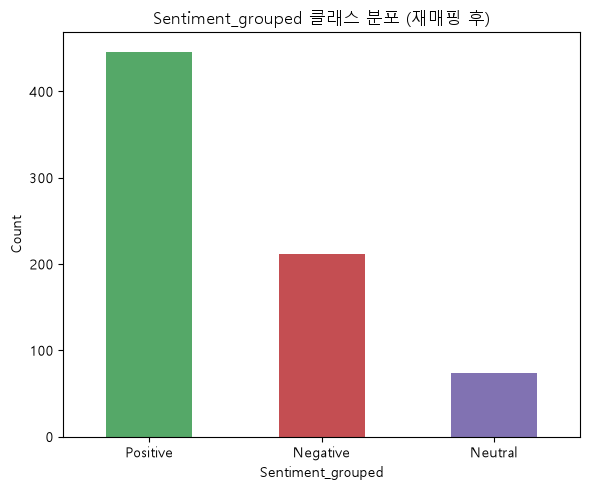

In [19]:
manual_override = {
    'Ambivalence': 'Neutral', 'Confusion': 'Neutral', 'Nostalgia': 'Neutral',
    'Bittersweet': 'Neutral', 'Curiosity': 'Neutral', 'Contemplation': 'Neutral',
    'Indifference': 'Neutral', 'Neutral': 'Neutral',
    # manual_review 결과를 검토한 뒤 계속 추가
}

manual_override.update({
    'Empowerment': 'Positive',
    'Resilience': 'Positive',
    'Solitude': 'Neutral',
    'Iconic': 'Positive',
    'Engagement': 'Positive',
})

final_mapping = dict(zip(polarity_df['label'], polarity_df['mapped_grouped']))
final_mapping.update(manual_override)

mapping_check_df = pd.DataFrame(
    list(final_mapping.items()), columns=['Sentiment_original', 'Sentiment_grouped']
).sort_values('Sentiment_grouped').reset_index(drop=True)

print("=== 6) 최종 매핑 딕셔너리 (전체) ===")
display(mapping_check_df)

df['Sentiment_original'] = df['Sentiment']
df['Sentiment_grouped'] = df['Sentiment'].map(final_mapping)

unmapped = df[df['Sentiment_grouped'].isna()]
print(f"\n=== 7) 매핑 누락 건수 : {len(unmapped)}건 ===")
if len(unmapped) > 0:
    display(unmapped[['Sentiment_original']].drop_duplicates())

after_dist = df['Sentiment_grouped'].value_counts()
after_ratio = df['Sentiment_grouped'].value_counts(normalize=True).round(3)

print("\n=== 8) 재매핑 후 (Sentiment_grouped) 클래스 분포 ===")
grouped_summary = pd.DataFrame({'count': after_dist, 'ratio': after_ratio})
display(grouped_summary)

plt.figure(figsize=(6, 5))
after_dist.plot(kind='bar', color=['#55A868', '#C44E52', '#8172B2'])
plt.title('Sentiment_grouped 클래스 분포 (재매핑 후)')
plt.xlabel('Sentiment_grouped')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2. EDA 분석

##### 2_1 Sentiment_grouped 클래스 분포

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import ast

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

=== 1) Sentiment_grouped 클래스 분포 ===


,count,ratio
Sentiment_grouped,,
Positive,446,0.609
Negative,212,0.290
Neutral,74,0.101


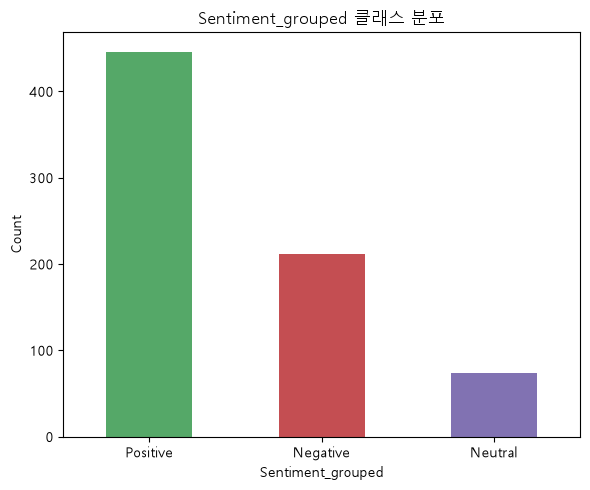

In [21]:
# ── 1) 클래스별 빈도 및 비율 집계 ────────────────────────────────
sentiment_dist = df['Sentiment_grouped'].value_counts()
sentiment_ratio = df['Sentiment_grouped'].value_counts(normalize=True).round(3)

sentiment_summary = pd.DataFrame({'count': sentiment_dist, 'ratio': sentiment_ratio})

print("=== 1) Sentiment_grouped 클래스 분포 ===")
display(sentiment_summary)

# ── 2) 클래스 분포 막대그래프 ──────────────────────────────────
plt.figure(figsize=(6, 5))
sentiment_dist.plot(kind='bar', color=['#55A868', '#C44E52', '#8172B2'])
plt.title('Sentiment_grouped 클래스 분포')
plt.xlabel('Sentiment_grouped')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### 2_2. Platform 별 감성 분포 (crosstab, stacked bar)


=== 1) Platform 별 감성 교차표 (빈도) ===


Sentiment_grouped,Negative,Neutral,Positive
Platform,,,
Facebook,64,26,141
Instagram,69,28,161
Twitter,79,20,144



=== 2) Platform 별 감성 비율 ===


Sentiment_grouped,Negative,Neutral,Positive
Platform,,,
Facebook,0.277,0.113,0.610
Instagram,0.267,0.109,0.624
Twitter,0.325,0.082,0.593


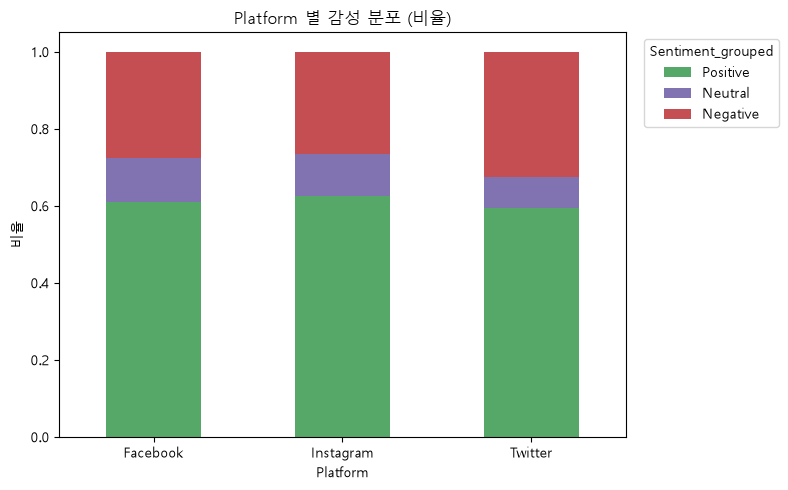

In [22]:
# ── 1) Platform × Sentiment_grouped 교차표 (빈도) ────────────────
platform_ct = pd.crosstab(df['Platform'], df['Sentiment_grouped'])

print("=== 1) Platform 별 감성 교차표 (빈도) ===")
display(platform_ct)

# ── 2) Platform 별 감성 비율 (행 기준 정규화) ────────────────────
platform_ct_ratio = pd.crosstab(
    df['Platform'], df['Sentiment_grouped'], normalize='index'
).round(3)

print("\n=== 2) Platform 별 감성 비율 ===")
display(platform_ct_ratio)

# ── 3) Stacked Bar Plot (비율 기준) ───────────────────────────────
plt.figure(figsize=(8, 5))
platform_ct_ratio[['Positive', 'Neutral', 'Negative']].plot(
    kind='bar', stacked=True,
    color=['#55A868', '#8172B2', '#C44E52'],
    ax=plt.gca()
)
plt.title('Platform 별 감성 분포 (비율)')
plt.xlabel('Platform')
plt.ylabel('비율')
plt.xticks(rotation=0)
plt.legend(title='Sentiment_grouped', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 2_3. Country 별 감성 분포 (crosstab, stacked bar)


=== 1) Country 별 표본 수 (상위 10개) ===


,count
Country,
USA,188
UK,143
Canada,135
Australia,75
India,70
Brazil,17
France,16
Japan,15
Germany,14



=== 2) Country 별 감성 교차표 (상위 10개국, 빈도) ===


Sentiment_grouped,Negative,Neutral,Positive
Country,,,
USA,52,14,122
UK,39,20,84
Canada,39,13,83
Australia,19,11,45
India,26,9,35
Brazil,7,0,10
France,7,0,9
Japan,3,2,10
Germany,6,1,7



=== 3) Country 별 감성 비율 (상위 10개국) ===


Sentiment_grouped,Negative,Neutral,Positive
Country,,,
USA,0.277,0.074,0.649
UK,0.273,0.140,0.587
Canada,0.289,0.096,0.615
Australia,0.253,0.147,0.600
India,0.371,0.129,0.500
Brazil,0.412,0.000,0.588
France,0.438,0.000,0.562
Japan,0.200,0.133,0.667
Germany,0.429,0.071,0.500


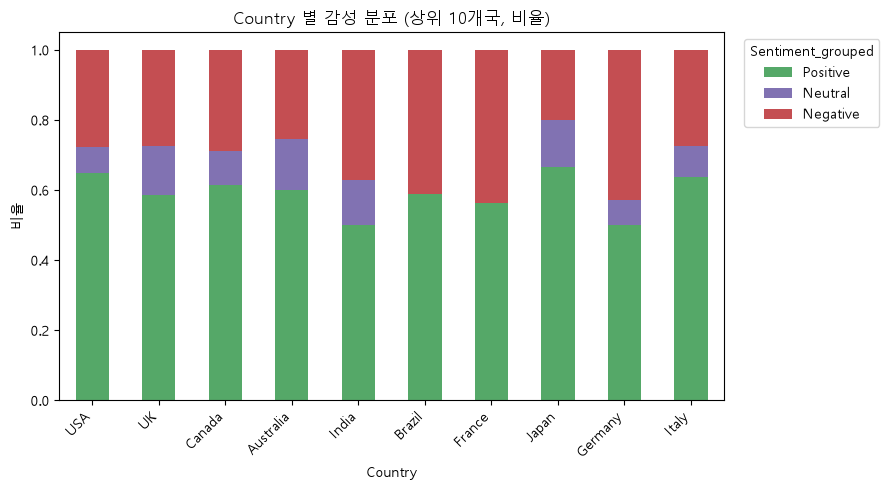

In [23]:
# ── 1) Country 별 표본 수 확인 (상위 N개국 선정용) ────────────────
country_counts = df['Country'].value_counts()
print("=== 1) Country 별 표본 수 (상위 10개) ===")
display(country_counts.head(10).to_frame('count'))

top_n = 10
top_countries = country_counts.head(top_n).index

# ── 2) 상위 N개국 × Sentiment_grouped 교차표 (빈도) ───────────────
country_ct = pd.crosstab(
    df[df['Country'].isin(top_countries)]['Country'],
    df[df['Country'].isin(top_countries)]['Sentiment_grouped']
).loc[top_countries]

print(f"\n=== 2) Country 별 감성 교차표 (상위 {top_n}개국, 빈도) ===")
display(country_ct)

# ── 3) 상위 N개국 감성 비율 (행 기준 정규화) ──────────────────────
country_ct_ratio = pd.crosstab(
    df[df['Country'].isin(top_countries)]['Country'],
    df[df['Country'].isin(top_countries)]['Sentiment_grouped'],
    normalize='index'
).loc[top_countries].round(3)

print(f"\n=== 3) Country 별 감성 비율 (상위 {top_n}개국) ===")
display(country_ct_ratio)

# ── 4) Stacked Bar Plot (비율 기준) ───────────────────────────────
plt.figure(figsize=(9, 5))
country_ct_ratio[['Positive', 'Neutral', 'Negative']].plot(
    kind='bar', stacked=True,
    color=['#55A868', '#8172B2', '#C44E52'],
    ax=plt.gca()
)
plt.title(f'Country 별 감성 분포 (상위 {top_n}개국, 비율)')
plt.xlabel('Country')
plt.ylabel('비율')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Sentiment_grouped', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 3_4. Hashtags 빈도 분석 - 전체 Top-N, Sentiment_grouped 별 Top-N 비교

=== 1) 전체 해시태그 Top-N 빈도 ===


,hashtag,count
0,#serenity,15
1,#gratitude,13
2,#excitement,13
3,#despair,11
4,#nostalgia,11
5,#contentment,10
6,#curiosity,10
7,#awe,9
8,#grief,9
9,#loneliness,9



=== 2) Sentiment_grouped 별 해시태그 Top-N 빈도 ===

[Positive]


,hashtag,count_Positive
0,#serenity,15
1,#gratitude,13
2,#excitement,13
3,#contentment,10
4,#awe,9
5,#hopeful,9
6,#enthusiasm,8
7,#joy,8
8,#acceptance,8
9,#inspiration,7



[Negative]


,hashtag,count_Negative
0,#despair,11
1,#grief,9
2,#loneliness,9
3,#elation,7
4,#euphoria,7
5,#bitterness,6
6,#regret,6
7,#numbness,6
8,#melancholy,6
9,#overwhelmed,5



[Neutral]


,hashtag,count_Neutral
0,#nostalgia,11
1,#curiosity,10
2,#confusion,8
3,#ambivalence,6
4,#indifference,5
5,#thoughtlabyrinth,2
6,#driftingthroughlife,2
7,#yearning,2
8,#contemplation,2
9,#ancientmysteries,2


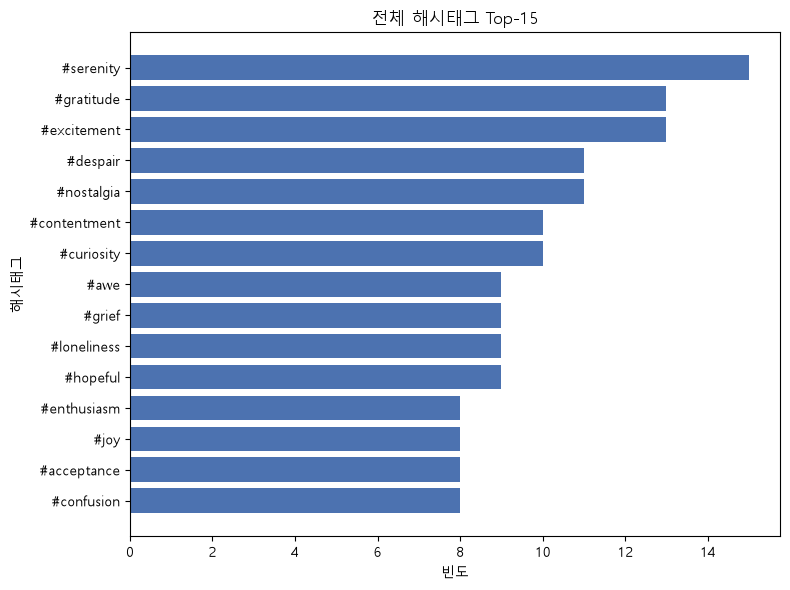

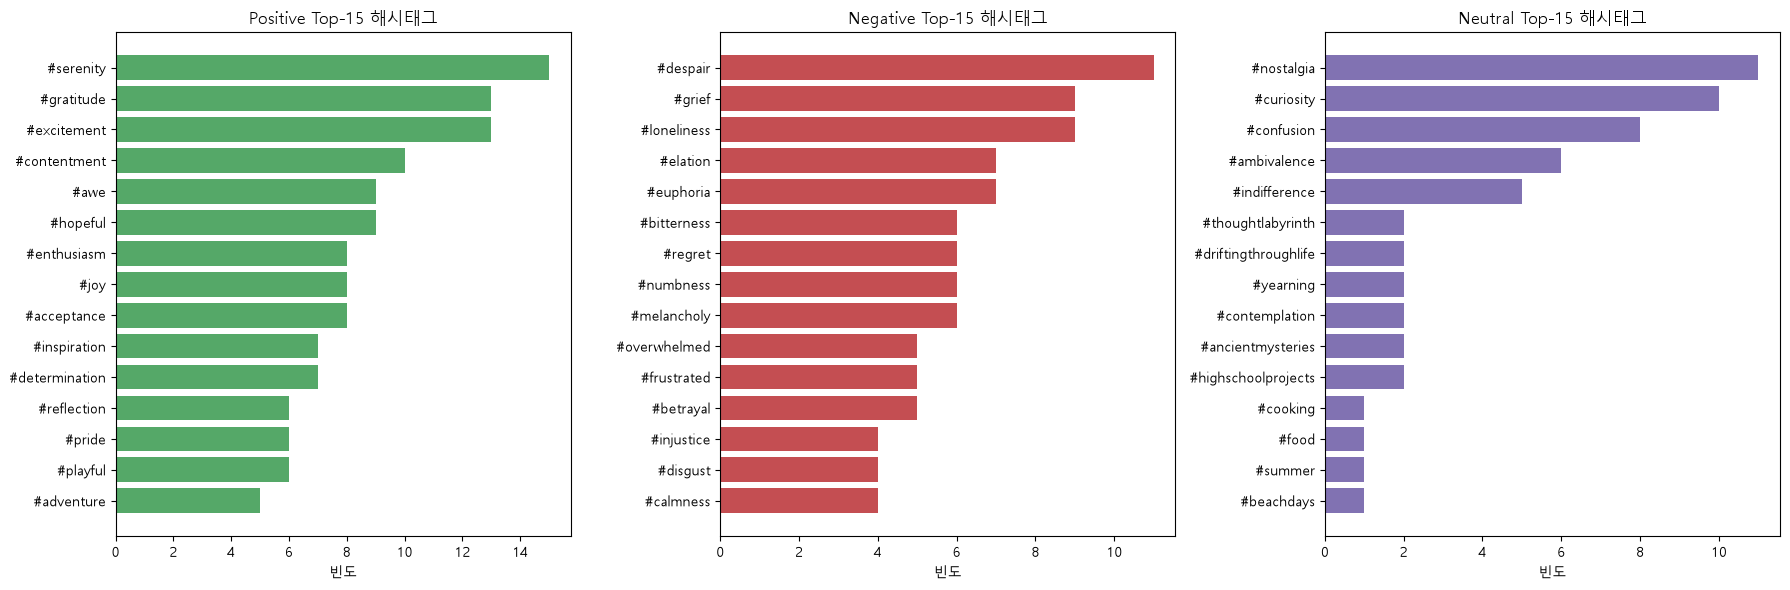

In [24]:
# ── 1) Hashtags 컬럼 파싱 함수 ─────────────────────────────────
# 원본 형태가 "['#AI', '#Tech']" 같은 문자열 리스트 또는
# "#AI #Tech" 같은 공백 구분 문자열일 수 있어 두 케이스 모두 방어적으로 처리
def parse_hashtags(raw):
    if pd.isna(raw):
        return []
    raw = str(raw).strip()
    if raw.startswith('[') and raw.endswith(']'):
        try:
            parsed = ast.literal_eval(raw)
            return [str(h).strip().lower() for h in parsed]
        except (ValueError, SyntaxError):
            pass
    return [tok.strip().lower() for tok in raw.replace(',', ' ').split() if tok.strip()]

df['Hashtags_list'] = df['Hashtags'].apply(parse_hashtags)

# ── 2) 전체 해시태그 Top-N 빈도 ────────────────────────────────
top_n = 15
all_hashtags = [tag for tags in df['Hashtags_list'] for tag in tags]
overall_counter = Counter(all_hashtags)

overall_top_df = pd.DataFrame(
    overall_counter.most_common(top_n), columns=['hashtag', 'count']
)

print("=== 1) 전체 해시태그 Top-N 빈도 ===")
display(overall_top_df)

# ── 3) Sentiment_grouped 별 해시태그 Top-N 빈도 ───────────────────
sentiment_hashtag_top = {}
for label in ['Positive', 'Negative', 'Neutral']:
    tags = [tag for tags in df.loc[df['Sentiment_grouped'] == label, 'Hashtags_list']
            for tag in tags]
    counter = Counter(tags)
    sentiment_hashtag_top[label] = pd.DataFrame(
        counter.most_common(top_n), columns=['hashtag', f'count_{label}']
    )

print("\n=== 2) Sentiment_grouped 별 해시태그 Top-N 빈도 ===")
for label, top_df in sentiment_hashtag_top.items():
    print(f"\n[{label}]")
    display(top_df)

# ── 4) 전체 Top-N 해시태그 막대그래프 ─────────────────────────────
plt.figure(figsize=(8, 6))
plt.barh(overall_top_df['hashtag'][::-1], overall_top_df['count'][::-1], color='#4C72B0')
plt.title(f'전체 해시태그 Top-{top_n}')
plt.xlabel('빈도')
plt.ylabel('해시태그')
plt.tight_layout()
plt.show()

# ── 5) Sentiment_grouped 별 Top-N 해시태그 비교 (서브플롯) ────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = {'Positive': '#55A868', 'Negative': '#C44E52', 'Neutral': '#8172B2'}

for ax, label in zip(axes, ['Positive', 'Negative', 'Neutral']):
    top_df = sentiment_hashtag_top[label]
    ax.barh(top_df['hashtag'][::-1], top_df[f'count_{label}'][::-1], color=colors[label])
    ax.set_title(f'{label} Top-{top_n} 해시태그')
    ax.set_xlabel('빈도')

plt.tight_layout()
plt.show()

##### 2_5. Retweets/Likes와 Sentiment_grouped 관계 (groupby 통계 + boxplot)



=== 1) Sentiment_grouped 별 Retweets/Likes 기술통계 ===


Retweets                     Likes                    
                      mean median   std count   mean median    std count
Sentiment_grouped                                                       
Negative             18.78   18.0  7.27   212  37.45   35.0  14.49   212
Neutral              19.04   19.5  6.52    74  38.01   38.5  12.88    74
Positive             23.22   22.0  6.51   446  46.30   45.0  13.03   446

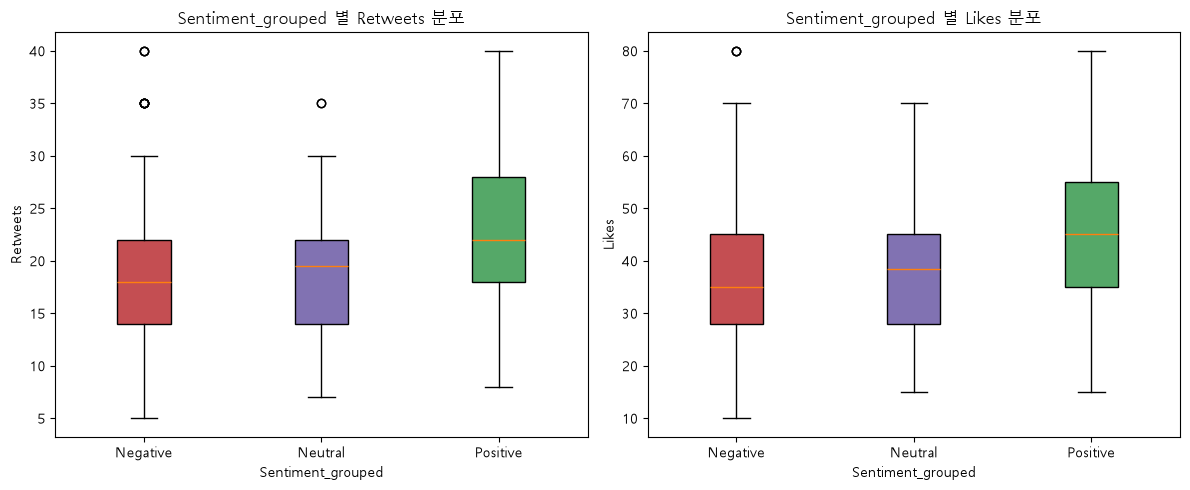

In [25]:
# ── 1) Sentiment_grouped 별 Retweets/Likes 기술통계 ───────────────
engagement_stats = df.groupby('Sentiment_grouped')[['Retweets', 'Likes']].agg(
    ['mean', 'median', 'std', 'count']
).round(2)

print("=== 1) Sentiment_grouped 별 Retweets/Likes 기술통계 ===")
display(engagement_stats)

# ── 2) Boxplot — Retweets / Likes ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

groups_order = ['Negative', 'Neutral', 'Positive']
retweet_data = [df.loc[df['Sentiment_grouped'] == g, 'Retweets'] for g in groups_order]
likes_data = [df.loc[df['Sentiment_grouped'] == g, 'Likes'] for g in groups_order]

box_colors = ['#C44E52', '#8172B2', '#55A868']

try:
    bp1 = axes[0].boxplot(retweet_data, tick_labels=groups_order, patch_artist=True)
    bp2 = axes[1].boxplot(likes_data, tick_labels=groups_order, patch_artist=True)
except TypeError:
    bp1 = axes[0].boxplot(retweet_data, labels=groups_order, patch_artist=True)
    bp2 = axes[1].boxplot(likes_data, labels=groups_order, patch_artist=True)

for patch, color in zip(bp1['boxes'], box_colors):
    patch.set_facecolor(color)
axes[0].set_title('Sentiment_grouped 별 Retweets 분포')
axes[0].set_xlabel('Sentiment_grouped')
axes[0].set_ylabel('Retweets')

for patch, color in zip(bp2['boxes'], box_colors):
    patch.set_facecolor(color)
axes[1].set_title('Sentiment_grouped 별 Likes 분포')
axes[1].set_xlabel('Sentiment_grouped')
axes[1].set_ylabel('Likes')

plt.tight_layout()
plt.show()

##### 2_6. Hour 별 감성 패턴 (crosstab, line plot)

=== 1) Hour 별 감성 교차표 (빈도) ===


Sentiment_grouped,Negative,Neutral,Positive
Hour,,,
0,0,0,1
2,1,0,0
3,3,0,0
5,0,0,1
6,0,0,4
7,0,0,7
8,4,3,16
9,14,4,10
10,7,6,17



=== 2) Hour 별 감성 비율 ===


Sentiment_grouped,Negative,Neutral,Positive
Hour,,,
0,0.000,0.000,1.000
2,1.000,0.000,0.000
3,1.000,0.000,0.000
5,0.000,0.000,1.000
6,0.000,0.000,1.000
7,0.000,0.000,1.000
8,0.174,0.130,0.696
9,0.500,0.143,0.357
10,0.233,0.200,0.567


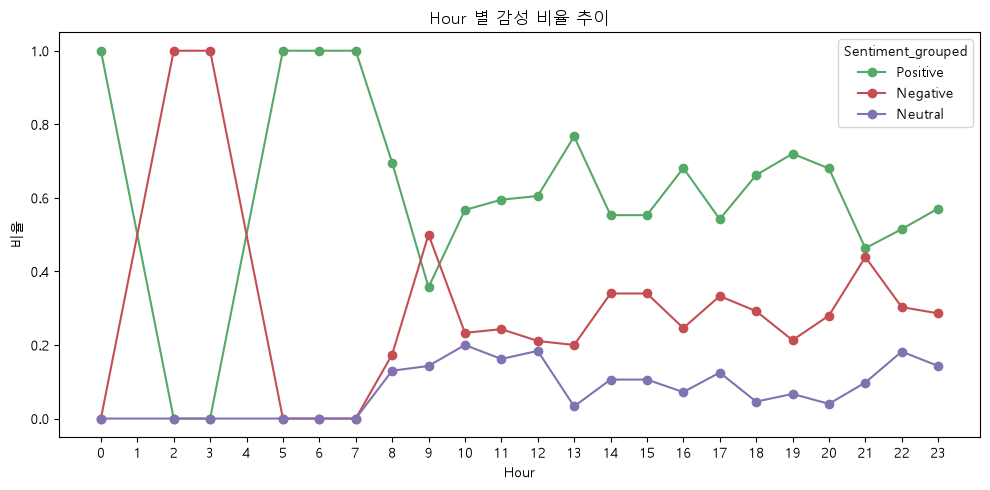

In [26]:
# ── 1) Hour × Sentiment_grouped 교차표 (빈도) ─────────────────────
hour_ct = pd.crosstab(df['Hour'], df['Sentiment_grouped']).sort_index()

print("=== 1) Hour 별 감성 교차표 (빈도) ===")
display(hour_ct)

# ── 2) Hour 별 감성 비율 (행 기준 정규화) ─────────────────────────
hour_ct_ratio = pd.crosstab(
    df['Hour'], df['Sentiment_grouped'], normalize='index'
).sort_index().round(3)

print("\n=== 2) Hour 별 감성 비율 ===")
display(hour_ct_ratio)

# ── 3) Line Plot — 시간대별 감성 비율 추이 ────────────────────────
plt.figure(figsize=(10, 5))
for label, color in zip(['Positive', 'Negative', 'Neutral'],
                          ['#55A868', '#C44E52', '#8172B2']):
    plt.plot(hour_ct_ratio.index, hour_ct_ratio[label],
              marker='o', label=label, color=color)

plt.title('Hour 별 감성 비율 추이')
plt.xlabel('Hour')
plt.ylabel('비율')
plt.xticks(range(0, 24))
plt.legend(title='Sentiment_grouped')
plt.tight_layout()
plt.show()

### 3. Text 전처리

##### 3_1. 사전 진단

In [27]:
import re

In [28]:
# ── 1) URL 패턴 존재 여부 (전체 732건 기준) ───────────────────────
url_pattern = re.compile(r'http\S+|www\.\S+')
url_count = df['Text'].apply(lambda x: len(url_pattern.findall(str(x)))).sum()

# ── 2) 멘션(@) 패턴 존재 여부 ──────────────────────────────────────
mention_pattern = re.compile(r'@\w+')
mention_count = df['Text'].apply(lambda x: len(mention_pattern.findall(str(x)))).sum()

# ── 3) 이모지 존재 여부 ────────────────────────────────────────────
emoji_pattern = re.compile(
    "[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F1E6-\U0001F1FF]"
)
emoji_count = df['Text'].apply(lambda x: len(emoji_pattern.findall(str(x)))).sum()

print("=== 1) Text 컬럼 특성 사전 진단 (전체 732건 기준) ===")
print(f"URL 포함 개수     : {url_count}")
print(f"멘션(@) 포함 개수  : {mention_count}")
print(f"이모지 포함 개수   : {emoji_count}")

if emoji_count > 0:
    print("\n=== 2) 이모지 포함 샘플 ===")
    display(df.loc[df['Text'].str.contains(emoji_pattern, na=False), 'Text'])

=== 1) Text 컬럼 특성 사전 진단 (전체 732건 기준) ===
URL 포함 개수     : 0
멘션(@) 포함 개수  : 0
이모지 포함 개수   : 11

=== 2) 이모지 포함 샘플 ===


2                   Just finished an amazing workout! 💪
13                       New year, new fitness goals! 💪
16                  Just adopted a cute furry friend! 🐾
24                   Celebrating a milestone at work! 🎉
29                          New painting in progress! 🎨
41           Celebrating a friend's birthday tonight! 🎂
50         Starting a new fitness challenge tomorrow! 💪
58    Sharing love and positive vibes with everyone! ❤️
67    Overflowing with adoration for my adorable pet! 🐾
82    Sending love to all my followers on this beaut...
91     Overflowing adoration for a cute rescue puppy! 🐶
Name: Text, dtype: str

##### 3_2. 전처리

In [29]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\82102\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [30]:
# ── 1) 이모지 → 텍스트 변환 함수 ──────────────────────────────────
# 이모지를 제거하지 않고 의미 있는 단어로 치환 (감성 정보 보존 → 모델 성능 향상 목적)
# 예: '💪' → 'flexed biceps', '❤️' → 'red heart'
try:
    import emoji
    def emoji_to_text(text):
        converted = emoji.demojize(text, delimiters=(' ', ' '))
        converted = converted.replace('_', ' ').replace(':', ' ')
        return converted
except ImportError:
    print("⚠️ emoji 패키지 미설치 — 이모지를 단순 제거하는 방식으로 대체합니다.")
    emoji_pattern_fallback = re.compile(
        "[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F1E6-\U0001F1FF]"
    )
    def emoji_to_text(text):
        return emoji_pattern_fallback.sub(' ', text)

# ── 2) 불용어/표제어 추출 도구 준비 ───────────────────────────────
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# ── 3) 전처리 파이프라인 함수 정의 ─────────────────────────────────
def preprocess_text(text):
    text = str(text)

    # 3-1. 이모지 → 텍스트 변환 (제거 대신 의미 보존, 예: 💪 → flexed biceps)
    text = emoji_to_text(text)

    # 3-2. 소문자화
    text = text.lower()

    # 3-3. 특수문자/숫자/구두점 제거 (알파벳과 공백만 남김)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 3-4. 연속 공백 정리
    text = re.sub(r'\s+', ' ', text).strip()

    # 3-5. 토큰화
    tokens = word_tokenize(text)

    # 3-6. 불용어 제거 + 표제어 추출 (2글자 이하 토큰도 함께 제거)
    tokens = [
        lemmatizer.lemmatize(tok) for tok in tokens
        if tok not in stop_words and len(tok) > 2
    ]

    return ' '.join(tokens)

# ── 4) 전체 Text 컬럼에 적용 ────────────────────────────────────
df['Text_clean'] = df['Text'].apply(preprocess_text)

# ── 5) 전처리 전/후 비교 샘플 확인 (일반 텍스트) ────────────────
print("=== 1) 전처리 전/후 비교 (상위 5건) ===")
display(df[['Text', 'Text_clean']].head(5))

# ── 6) 이모지 포함 행 전/후 비교 (11건 전체, 이모지 변환 검증) ─────
emoji_pattern = re.compile(
    "[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F1E6-\U0001F1FF]"
)
emoji_idx = df[df['Text'].str.contains(emoji_pattern, na=False)].index

print(f"\n=== 2) 이모지 포함 행 전/후 비교 (전체 {len(emoji_idx)}건) ===")
display(df.loc[emoji_idx, ['Text', 'Text_clean']])

# ── 7) 전처리 후 빈 문자열(공백만 남은 행) 확인 ────────────────────
empty_after = df[df['Text_clean'].str.strip() == '']
print(f"\n=== 3) 전처리 후 빈 문자열이 된 행 : {len(empty_after)}건 ===")
if len(empty_after) > 0:
    display(empty_after[['Text']])

# ── 8) 전처리 후 텍스트 평균 토큰 수 확인 ──────────────────────────
avg_tokens = df['Text_clean'].apply(lambda x: len(x.split())).mean()
print(f"\n=== 4) 전처리 후 평균 토큰 수 : {avg_tokens:.2f}개 ===")

=== 1) 전처리 전/후 비교 (상위 5건) ===


,Text,Text_clean
0,Enjoying a beautiful day at the park!,enjoying beautiful day park
1,Traffic was terrible this morning.,traffic terrible morning
2,Just finished an amazing workout! 💪,finished amazing workout flexed biceps
3,Excited about the upcoming weekend getaway!,excited upcoming weekend getaway
4,Trying out a new recipe for dinner tonight.,trying new recipe dinner tonight



=== 2) 이모지 포함 행 전/후 비교 (전체 11건) ===


,Text,Text_clean
2,Just finished an amazing workout! 💪,finished amazing workout flexed biceps
13,"New year, new fitness goals! 💪",new year new fitness goal flexed biceps
16,Just adopted a cute furry friend! 🐾,adopted cute furry friend paw print
24,Celebrating a milestone at work! 🎉,celebrating milestone work party popper
29,New painting in progress! 🎨,new painting progress artist palette
41,Celebrating a friend's birthday tonight! 🎂,celebrating friend birthday tonight birthday cake
50,Starting a new fitness challenge tomorrow! 💪,starting new fitness challenge tomorrow flexed...
58,Sharing love and positive vibes with everyone! ❤️,sharing love positive vibe everyone red heart
67,Overflowing with adoration for my adorable pet! 🐾,overflowing adoration adorable pet paw print
82,Sending love to all my followers on this beaut...,sending love follower beautiful day red heart



=== 3) 전처리 후 빈 문자열이 된 행 : 0건 ===

=== 4) 전처리 후 평균 토큰 수 : 8.15개 ===


### 4. Feature Engineering

##### 4-1. 텍스트 벡터화 (TF-IDF, 1-2 gram)

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [32]:
# ── 1) TF-IDF 벡터화 (Unigram + Bigram) ──────────────────────────
# max_features로 희소 차원 폭증 방지, min_df로 희귀 토큰(노이즈) 제거
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=3000,
    min_df=2,
    max_df=0.95
)
X_text_tfidf = tfidf_vectorizer.fit_transform(df['Text_clean'])

print("=== 1) TF-IDF 벡터화 결과 ===")
print("행렬 shape:", X_text_tfidf.shape)
print("전체 어휘 수(선택된 max_features 내):", len(tfidf_vectorizer.vocabulary_))

# ── 2) 주요 TF-IDF 피처(어휘) 샘플 확인 ───────────────────────────
tfidf_feature_names = tfidf_vectorizer.get_feature_names_out()
sample_features = pd.DataFrame({
    'feature': tfidf_feature_names[:15]
})
print("\n=== 2) TF-IDF 피처 샘플 (상위 15개, 알파벳순) ===")
display(sample_features)

# ── 3) Bigram 비율 확인 (1-2gram 적용 여부 검증) ──────────────────
bigram_count = sum(1 for f in tfidf_feature_names if ' ' in f)
unigram_count = len(tfidf_feature_names) - bigram_count
print(f"\n=== 3) N-gram 구성 비율 ===")
print(f"Unigram : {unigram_count}개 ({unigram_count/len(tfidf_feature_names):.1%})")
print(f"Bigram  : {bigram_count}개 ({bigram_count/len(tfidf_feature_names):.1%})")

=== 1) TF-IDF 벡터화 결과 ===
행렬 shape: (732, 1541)
전체 어휘 수(선택된 max_features 내): 1541

=== 2) TF-IDF 피처 샘플 (상위 15개, 알파벳순) ===


,feature
0,abstract
1,abstract art
2,abyss
3,abyss despair
4,academic
5,acceptance
6,acceptance mosaic
7,accidentally
8,accidentally sent
9,accomplished



=== 3) N-gram 구성 비율 ===
Unigram : 1033개 (67.0%)
Bigram  : 508개 (33.0%)


##### 4-2. 메타데이터 Ft — Platform, Country 원-핫 인코딩

In [33]:
# ── 1) Platform 카디널리티 확인 ─────────────────────────────────
platform_ratio = df['Platform'].value_counts(normalize=True).round(3)
print("=== 1) Platform 범주별 비율 ===")
display(platform_ratio.to_frame('ratio'))
# → 모든 범주 충분한 비중 확인 → 그룹화 없이 원형 유지

# ── 2) Country 카디널리티 확인 및 저빈도 범주 그룹화 ───────────────
# 첨부 원본 코드의 country_region 그룹화 방식과 동일하게,
# 비율 3% 미만인 국가는 'Other'로 통합하여 원-핫 차원 폭증 방지
country_ratio = df['Country'].value_counts(normalize=True).round(3)
print("\n=== 2) Country 범주별 비율 (그룹화 전) ===")
display(country_ratio.to_frame('ratio'))

rare_countries = country_ratio[country_ratio < 0.03].index.tolist()
print(f"\n'Other'로 통합되는 국가 ({len(rare_countries)}개): {rare_countries}")

df['Country_grouped'] = df['Country'].apply(
    lambda x: 'Other' if x in rare_countries else x
)

country_grouped_ratio = df['Country_grouped'].value_counts(normalize=True).round(3)
print("\n=== 3) Country_grouped 범주별 비율 (그룹화 후) ===")
display(country_grouped_ratio.to_frame('ratio'))

# ── 3) 명목형 변수 원-핫 인코딩 (drop_first=True, 첨부 원본 방식 동일) ──
meta_nominal_df = pd.get_dummies(
    df[['Platform', 'Country_grouped']],
    columns=['Platform', 'Country_grouped'],
    drop_first=True
)

print(f"\n=== 4) Platform/Country 원-핫 인코딩 결과 ===")
print("생성된 컬럼 수:", meta_nominal_df.shape[1])
display(meta_nominal_df.head())

=== 1) Platform 범주별 비율 ===


,ratio
Platform,
Instagram,0.352
Twitter,0.332
Facebook,0.316



=== 2) Country 범주별 비율 (그룹화 전) ===


,ratio
Country,
USA,0.257
UK,0.195
Canada,0.184
Australia,0.102
India,0.096
Brazil,0.023
France,0.022
Japan,0.020
Germany,0.019



'Other'로 통합되는 국가 (28개): ['Brazil', 'France', 'Japan', 'Germany', 'Italy', 'South Africa', 'Spain', 'Greece', 'Netherlands', 'Switzerland', 'Sweden', 'Portugal', 'Austria', 'Belgium', 'Denmark', 'Czech Republic', 'Jordan', 'Peru', 'Maldives', 'China', 'Cambodia', 'Norway', 'Colombia', 'Ireland', 'Jamaica', 'Kenya', 'Scotland', 'Thailand']

=== 3) Country_grouped 범주별 비율 (그룹화 후) ===


,ratio
Country_grouped,
USA,0.257
UK,0.195
Canada,0.184
Other,0.165
Australia,0.102
India,0.096



=== 4) Platform/Country 원-핫 인코딩 결과 ===
생성된 컬럼 수: 7


,Platform_Instagram,Platform_Twitter,Country_grouped_Canada,Country_grouped_India,Country_grouped_Other,Country_grouped_UK,Country_grouped_USA
0,False,True,False,False,False,False,True
1,False,True,True,False,False,False,False
2,True,False,False,False,False,False,True
3,False,False,False,False,False,True,False
4,True,False,False,False,False,False,False


##### 4-3. 메타데이터 Ft — Hashtags 개수/주요 키워드 이진화

In [34]:
# ── 1) 해시태그 개수 파생변수 ─────────────────────────────────────
# Hashtags_list 컬럼은 EDA(6-4) 단계에서 이미 파싱 완료
df['hashtag_count'] = df['Hashtags_list'].apply(len)

print("=== 1) hashtag_count 기술통계 ===")
display(df['hashtag_count'].describe().round(2).to_frame('value'))

# ── 2) 주요 키워드 선정 (EDA 6-4의 전체 Top-N 해시태그 재사용) ────
# 상위 TOP_K개 해시태그에 대해 등장 여부를 이진(0/1) 피처로 생성
TOP_K_HASHTAGS = 10
top_k_tags = [tag for tag, _ in overall_counter.most_common(TOP_K_HASHTAGS)]

print(f"\n=== 2) 이진화 대상 Top-{TOP_K_HASHTAGS} 해시태그 ===")
display(pd.DataFrame({'hashtag': top_k_tags}))

hashtag_binary_df = pd.DataFrame(index=df.index)
for tag in top_k_tags:
    col_name = f"hashtag_has_{re.sub(r'[^a-z0-9]', '', tag)}"
    hashtag_binary_df[col_name] = df['Hashtags_list'].apply(
        lambda tags, t=tag: int(t in tags)
    )

print(f"\n=== 3) 해시태그 이진화 피처 샘플 ===")
display(hashtag_binary_df.head())

# ── 3) hashtag_count + 이진화 피처 결합 ───────────────────────────
hashtag_feature_df = pd.concat(
    [df[['hashtag_count']], hashtag_binary_df], axis=1
)
print(f"\n=== 4) 최종 Hashtags 파생 피처 shape: {hashtag_feature_df.shape} ===")

=== 1) hashtag_count 기술통계 ===


,value
count,732.0
mean,2.0
std,0.0
min,2.0
25%,2.0
50%,2.0
75%,2.0
max,2.0



=== 2) 이진화 대상 Top-10 해시태그 ===


,hashtag
0,#serenity
1,#gratitude
2,#excitement
3,#despair
4,#nostalgia
5,#contentment
6,#curiosity
7,#awe
8,#grief
9,#loneliness



=== 3) 해시태그 이진화 피처 샘플 ===


,hashtag_has_serenity,hashtag_has_gratitude,hashtag_has_excitement,hashtag_has_despair,hashtag_has_nostalgia,hashtag_has_contentment,hashtag_has_curiosity,hashtag_has_awe,hashtag_has_grief,hashtag_has_loneliness
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0



=== 4) 최종 Hashtags 파생 피처 shape: (732, 11) ===


##### 4-4. 메타데이터 Ft — Likes/Retweets 정규화 (StandardScaler)

In [35]:
from sklearn.preprocessing import StandardScaler

In [36]:
# ── 1) 정규화 전 분포 확인 ───────────────────────────────────────
print("=== 1) Likes/Retweets 정규화 전 기술통계 ===")
display(df[['Likes', 'Retweets']].describe().round(2))

# ── 2) StandardScaler 적용 ────────────────────────────────────────
engagement_scaler = StandardScaler()
engagement_scaled_arr = engagement_scaler.fit_transform(df[['Likes', 'Retweets']])

engagement_scaled_df = pd.DataFrame(
    engagement_scaled_arr,
    columns=['Likes_scaled', 'Retweets_scaled'],
    index=df.index
)

print("\n=== 2) 정규화 후 기술통계 (평균 0, 표준편차 1 확인) ===")
display(engagement_scaled_df.describe().round(3))

=== 1) Likes/Retweets 정규화 전 기술통계 ===


,Likes,Retweets
count,732.00,732.00
mean,42.90,21.51
std,14.09,7.06
min,10.00,5.00
25%,34.75,17.75
50%,43.00,22.00
75%,50.00,25.00
max,80.00,40.00



=== 2) 정규화 후 기술통계 (평균 0, 표준편차 1 확인) ===


,Likes_scaled,Retweets_scaled
count,732.000,732.000
mean,0.000,0.000
std,1.001,1.001
min,-2.337,-2.339
25%,-0.579,-0.533
50%,0.007,0.070
75%,0.504,0.495
max,2.635,2.621


##### 4-5. 메타데이터 Ft — Year/Month/Day/Hour → 요일/시간대 파생변수화

In [37]:
# ── 1) Year/Month/Day → 날짜(Date) 및 요일(day_of_week) 파생 ──────
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])
df['day_of_week'] = df['Date'].dt.day_name()

print("=== 1) day_of_week 분포 ===")
display(df['day_of_week'].value_counts().to_frame('count'))

# ── 2) Hour → 시간대 구간(time_period) 파생 ───────────────────────
# 0~5시: Night, 6~11시: Morning, 12~17시: Afternoon, 18~23시: Evening
def get_time_period(hour):
    if 0 <= hour < 6:
        return 'Night'
    elif 6 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 18:
        return 'Afternoon'
    else:
        return 'Evening'

df['time_period'] = df['Hour'].apply(get_time_period)

print("\n=== 2) time_period 분포 ===")
display(df['time_period'].value_counts().to_frame('count'))

# ── 3) 원-핫 인코딩 필요성 판단 ────────────────────────────────────
# day_of_week(7개), time_period(4개) 모두 순서/등간 척도가 아닌 명목형 범주이며
# (요일·시간대와 감성 간 관계가 선형적으로 증가/감소한다고 가정하기 어려움)
# 카디널리티도 크지 않으므로(7개, 4개) One-Hot 인코딩이 적절 → 진행
print("\n=== 3) 판단 결과: day_of_week, time_period 모두 명목형(One-Hot 적용) ===")

time_nominal_df = pd.get_dummies(
    df[['day_of_week', 'time_period']],
    columns=['day_of_week', 'time_period'],
    drop_first=True
)

print(f"\n=== 4) 시간 파생변수 원-핫 인코딩 결과 (컬럼 수: {time_nominal_df.shape[1]}) ===")
display(time_nominal_df.head())

=== 1) day_of_week 분포 ===


,count
day_of_week,
Sunday,119
Saturday,115
Tuesday,110
Friday,108
Monday,97
Thursday,95
Wednesday,88



=== 2) time_period 분포 ===


,count
time_period,
Afternoon,326
Evening,271
Morning,129
Night,6



=== 3) 판단 결과: day_of_week, time_period 모두 명목형(One-Hot 적용) ===

=== 4) 시간 파생변수 원-핫 인코딩 결과 (컬럼 수: 9) ===


,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday,time_period_Evening,time_period_Morning,time_period_Night
0,False,False,True,False,False,False,False,False,False
1,False,False,True,False,False,False,False,True,False
2,False,False,True,False,False,False,False,False,False
3,False,False,True,False,False,False,True,False,False
4,False,False,True,False,False,False,True,False,False


##### 4-6. 최종 결합 — TF-IDF + 메타데이터 (scipy.sparse.hstack)

In [38]:
from scipy.sparse import hstack, csr_matrix

In [39]:
# ── 1) 각 피처 블록을 sparse 행렬로 변환 ──────────────────────────
X_meta_nominal = csr_matrix(meta_nominal_df.values.astype(float))       # Platform, Country
X_hashtag = csr_matrix(hashtag_feature_df.values.astype(float))          # hashtag_count + 이진화
X_engagement = csr_matrix(engagement_scaled_df.values.astype(float))     # Likes/Retweets 정규화
X_time = csr_matrix(time_nominal_df.values.astype(float))                # day_of_week, time_period

# ── 2) scipy.sparse.hstack으로 전체 결합 ──────────────────────────
X_combined = hstack([
    X_text_tfidf,     # TF-IDF (1-2gram)
    X_meta_nominal,   # Platform, Country 원-핫
    X_hashtag,        # Hashtags 파생
    X_engagement,     # Likes/Retweets 정규화
    X_time            # 요일/시간대 원-핫
]).tocsr()

# ── 3) 전체 피처명 리스트 구성 (추후 중요도 해석용) ────────────────
combined_feature_names = (
    list(tfidf_vectorizer.get_feature_names_out()) +
    list(meta_nominal_df.columns) +
    list(hashtag_feature_df.columns) +
    list(engagement_scaled_df.columns) +
    list(time_nominal_df.columns)
)

print("=== 1) 최종 결합 피처 행렬 ===")
print("X_combined shape:", X_combined.shape)
print("피처명 개수:", len(combined_feature_names))
assert X_combined.shape[1] == len(combined_feature_names), "⚠️ 차원 불일치!"

# ── 4) 블록별 차원 요약표 ─────────────────────────────────────────
block_summary = pd.DataFrame({
    'block': ['TF-IDF(Text)', 'Platform/Country', 'Hashtags', 'Likes/Retweets', 'Time(요일/시간대)'],
    'n_features': [
        X_text_tfidf.shape[1], X_meta_nominal.shape[1],
        X_hashtag.shape[1], X_engagement.shape[1], X_time.shape[1]
    ]
})
print("\n=== 2) 블록별 피처 차원 요약 ===")
display(block_summary)

# ── 5) target 변수 준비 (다음 모델링 단계용) ──────────────────────
y_combined = df['Sentiment_grouped']
print(f"\n=== 3) Target(y) shape: {y_combined.shape} ===")

=== 1) 최종 결합 피처 행렬 ===
X_combined shape: (732, 1570)
피처명 개수: 1570

=== 2) 블록별 피처 차원 요약 ===


,block,n_features
0,TF-IDF(Text),1541
1,Platform/Country,7
2,Hashtags,11
3,Likes/Retweets,2
4,Time(요일/시간대),9



=== 3) Target(y) shape: (732,) ===


### 5. SVM 모델링

##### 5-0. Train/Test 분할 (Stratified)

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y_combined,
    test_size=0.2,
    random_state=42,
    stratify=y_combined
)

print("=== 1) Train/Test 분할 결과 ===")
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("\n=== 2) Train 클래스 분포 ===")
display(y_train.value_counts(normalize=True).round(3).to_frame('ratio'))

print("\n=== 3) Test 클래스 분포 ===")
display(y_test.value_counts(normalize=True).round(3).to_frame('ratio'))

=== 1) Train/Test 분할 결과 ===
X_train shape: (585, 1570)
X_test shape : (147, 1570)

=== 2) Train 클래스 분포 ===


,ratio
Sentiment_grouped,
Positive,0.610
Negative,0.289
Neutral,0.101



=== 3) Test 클래스 분포 ===


,ratio
Sentiment_grouped,
Positive,0.605
Negative,0.293
Neutral,0.102


##### 5-1. 스케일 보정 — hashtag_count 미정규화 문제 해결 (MaxAbsScaler)


In [42]:
# ※ TF-IDF, Likes/Retweets는 이미 정규화 완료 → hashtag_count만 스케일 안 맞는 상태였음
# ※ sparse 행렬 호환 + 데이터 누수 방지를 위해 train 기준으로 fit, test는 transform만

from sklearn.preprocessing import MaxAbsScaler

scaler_final = MaxAbsScaler()
X_train_scaled = scaler_final.fit_transform(X_train)
X_test_scaled = scaler_final.transform(X_test)

print("=== 1) 최종 스케일 보정 완료 ===")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

=== 1) 최종 스케일 보정 완료 ===
X_train_scaled shape: (585, 1570)
X_test_scaled shape : (147, 1570)


##### 5-2. SVM 모델링 — Linear 커널 우선 + GridSearchCV(C) + StratifiedKFold

In [43]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score

In [44]:
# ── 1) 교차검증 설정 (StratifiedKFold, 앞선 다른 모델과 동일한 방식) ──
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── 2) Linear SVM + GridSearchCV (C만 튜닝) ───────────────────────
param_grid_linear = {'C': [0.01, 0.1, 1, 10, 100]}

svm_linear = SVC(kernel='linear', class_weight='balanced', random_state=42)

grid_linear = GridSearchCV(
    estimator=svm_linear,
    param_grid=param_grid_linear,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1
)
grid_linear.fit(X_train_scaled, y_train)

print("=== 1) Linear SVM 최적 하이퍼파라미터 ===")
print("Best C:", grid_linear.best_params_['C'])
print("Best CV Macro F1:", round(grid_linear.best_score_, 4))

# ── 3) OvO 방식 확인 (SVC 기본값) ─────────────────────────────────
best_svm_linear = grid_linear.best_estimator_
print("\n=== 2) 다중분류 방식 확인 ===")
print("decision_function_shape:", best_svm_linear.decision_function_shape)
print("학습된 이진분류기 개수 (3-class OvO → 3개):", len(best_svm_linear.classes_) *
      (len(best_svm_linear.classes_) - 1) // 2)

# ── 4) Test셋 평가 ────────────────────────────────────────────────
y_pred_linear = best_svm_linear.predict(X_test_scaled)

print("\n=== 3) Linear SVM Test 성능 ===")
print(classification_report(y_test, y_pred_linear))

print("=== 4) Confusion Matrix (Linear SVM) ===")
cm_linear = confusion_matrix(y_test, y_pred_linear, labels=best_svm_linear.classes_)
display(pd.DataFrame(cm_linear, index=best_svm_linear.classes_, columns=best_svm_linear.classes_))

=== 1) Linear SVM 최적 하이퍼파라미터 ===
Best C: 1
Best CV Macro F1: 0.7233

=== 2) 다중분류 방식 확인 ===
decision_function_shape: ovr
학습된 이진분류기 개수 (3-class OvO → 3개): 3

=== 3) Linear SVM Test 성능 ===
              precision    recall  f1-score   support

    Negative       0.87      0.79      0.83        43
     Neutral       0.89      0.53      0.67        15
    Positive       0.85      0.94      0.89        89

    accuracy                           0.86       147
   macro avg       0.87      0.76      0.80       147
weighted avg       0.86      0.86      0.85       147

=== 4) Confusion Matrix (Linear SVM) ===


,Negative,Neutral,Positive
Negative,34,0,9
Neutral,1,8,6
Positive,4,1,84


##### 5-3. (필요시) RBF 커널 비교 — GridSearchCV(C, gamma)

In [45]:
# ※ Linear 성능이 충분하면 이 단계는 생략 가능

param_grid_rbf = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

svm_rbf = SVC(kernel='rbf', class_weight='balanced', random_state=42)

grid_rbf = GridSearchCV(
    estimator=svm_rbf,
    param_grid=param_grid_rbf,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1
)
grid_rbf.fit(X_train_scaled, y_train)

print("=== 1) RBF SVM 최적 하이퍼파라미터 ===")
print("Best params:", grid_rbf.best_params_)
print("Best CV Macro F1:", round(grid_rbf.best_score_, 4))

best_svm_rbf = grid_rbf.best_estimator_
y_pred_rbf = best_svm_rbf.predict(X_test_scaled)

print("\n=== 2) RBF SVM Test 성능 ===")
print(classification_report(y_test, y_pred_rbf))

=== 1) RBF SVM 최적 하이퍼파라미터 ===
Best params: {'C': 10, 'gamma': 0.01}
Best CV Macro F1: 0.7271

=== 2) RBF SVM Test 성능 ===
              precision    recall  f1-score   support

    Negative       0.84      0.72      0.78        43
     Neutral       0.89      0.53      0.67        15
    Positive       0.83      0.94      0.88        89

    accuracy                           0.84       147
   macro avg       0.85      0.73      0.78       147
weighted avg       0.84      0.84      0.83       147



##### 5-4. Linear vs RBF 최종 비교 및 모델 선택

In [46]:
comparison_df = pd.DataFrame({
    'kernel': ['linear', 'rbf'],
    'best_params': [grid_linear.best_params_, grid_rbf.best_params_],
    'cv_macro_f1': [grid_linear.best_score_, grid_rbf.best_score_],
    'test_macro_f1': [
        f1_score(y_test, y_pred_linear, average='macro'),
        f1_score(y_test, y_pred_rbf, average='macro')
    ]
}).round(4)

print("=== 1) Linear vs RBF 최종 비교 ===")
display(comparison_df)

# ── 성능이 더 좋은 커널을 최종 모델로 선정 ─────────────────────────
final_kernel = comparison_df.loc[comparison_df['test_macro_f1'].idxmax(), 'kernel']
final_svm_model = best_svm_linear if final_kernel == 'linear' else best_svm_rbf

print(f"\n=== 2) 최종 선택 모델: SVM ({final_kernel} kernel) ===")

=== 1) Linear vs RBF 최종 비교 ===


,kernel,best_params,cv_macro_f1,test_macro_f1
0,linear,{'C': 1},0.7233,0.7965
1,rbf,"{'C': 10, 'gamma': 0.01}",0.7271,0.7753



=== 2) 최종 선택 모델: SVM (linear kernel) ===


### 6. 결과 해석 및 후속 분석

##### 6-1. Linear SVM coef_ 로 감성 예측 핵심 단어/n-gram 도출

In [47]:
# ※ SVC(kernel='linear')는 3-class OvO 방식이므로 coef_ shape = (3, n_features)
#   → 3개의 이진분류기(Positive vs Negative, Positive vs Neutral, Negative vs Neutral) 각각의 계수

from itertools import combinations

# ── 1) 최종 선택된 Linear SVM 모델 (linear가 아니면 별도 linear 모델 재확인용) ──
svm_for_coef = best_svm_linear  # linear 커널 모델 (coef_ 확인은 linear만 가능)

print("=== 1) coef_ 행렬 shape 확인 ===")
print("coef_ shape:", svm_for_coef.coef_.shape)
print("클래스 목록:", svm_for_coef.classes_)

# ── 2) OvO 이진분류기 쌍(class pair) 매핑 ─────────────────────────
class_pairs = list(combinations(svm_for_coef.classes_, 2))
print("\n=== 2) OvO 이진분류기 쌍 ===")
for i, pair in enumerate(class_pairs):
    print(f"  [{i}] {pair[0]} vs {pair[1]}")

# ── 3) 각 쌍별 Top-N 핵심 단어/n-gram 도출 ────────────────────────
TOP_N_WORDS = 15
coef_array = svm_for_coef.coef_.toarray() if hasattr(svm_for_coef.coef_, 'toarray') else svm_for_coef.coef_

for i, (class_a, class_b) in enumerate(class_pairs):
    coefs = coef_array[i]
    top_idx_a = coefs.argsort()[-TOP_N_WORDS:][::-1]   # class_a 쪽으로 미는 단어 (양수)
    top_idx_b = coefs.argsort()[:TOP_N_WORDS]           # class_b 쪽으로 미는 단어 (음수)

    result_df = pd.DataFrame({
        f'Top_{class_a}': [combined_feature_names[j] for j in top_idx_a],
        f'coef_{class_a}': coefs[top_idx_a].round(3),
        f'Top_{class_b}': [combined_feature_names[j] for j in top_idx_b],
        f'coef_{class_b}': coefs[top_idx_b].round(3)
    })

    print(f"\n=== 3-{i+1}) {class_a} vs {class_b} 핵심 단어/n-gram (Top {TOP_N_WORDS}) ===")
    display(result_df)

=== 1) coef_ 행렬 shape 확인 ===
coef_ shape: (3, 1570)
클래스 목록: ['Negative' 'Neutral' 'Positive']

=== 2) OvO 이진분류기 쌍 ===
  [0] Negative vs Neutral
  [1] Negative vs Positive
  [2] Neutral vs Positive

=== 3-1) Negative vs Neutral 핵심 단어/n-gram (Top 15) ===


,Top_Negative,coef_Negative,Top_Neutral,coef_Neutral
0,bad,0.442,hashtag_has_nostalgia,-0.697
1,personal,0.417,confusion,-0.638
2,whisper,0.415,attending,-0.633
3,regret,0.406,exploring,-0.615
4,dealing,0.396,oops,-0.603
5,feeling,0.331,hashtag_has_curiosity,-0.592
6,wall,0.326,indifference,-0.541
7,hashtag_has_loneliness,0.316,new,-0.533
8,like,0.311,club,-0.518
9,society,0.310,community,-0.517



=== 3-2) Negative vs Positive 핵심 단어/n-gram (Top 15) ===


,Top_Negative,coef_Negative,Top_Positive,coef_Positive
0,elation,1.131,pride,-0.783
1,bad,1.011,determination,-0.761
2,euphoria,0.991,tonight,-0.676
3,snack,0.987,embracing,-0.668
4,morning,0.787,championship,-0.623
5,jealousy,0.758,delight,-0.604
6,dealing,0.725,week,-0.583
7,frustration,0.719,perfect,-0.574
8,hold,0.701,hashtag_has_awe,-0.558
9,without,0.666,reflecting,-0.547



=== 3-3) Neutral vs Positive 핵심 단어/n-gram (Top 15) ===


,Top_Neutral,coef_Neutral,Top_Positive,coef_Positive
0,new recipe,0.887,virtual reality,-0.634
1,hashtag_has_nostalgia,0.862,inspired,-0.546
2,enhance,0.828,reality,-0.541
3,indifference,0.700,acceptance,-0.493
4,attending virtual,0.686,feeling,-0.463
5,oops,0.674,empowered,-0.404
6,saturday,0.674,compassion,-0.376
7,hashtag_has_curiosity,0.665,coding,-0.366
8,neighborhood,0.652,enthusiasm,-0.363
9,attending,0.651,joy,-0.356


##### 6-2. Hour / 요일 별 감성 트렌드 확인 (3-class 기준)

=== 1) Hour 별 감성 비율 ===


Sentiment_grouped,Negative,Neutral,Positive
Hour,,,
0,0.000,0.000,1.000
2,1.000,0.000,0.000
3,1.000,0.000,0.000
5,0.000,0.000,1.000
6,0.000,0.000,1.000
7,0.000,0.000,1.000
8,0.174,0.130,0.696
9,0.500,0.143,0.357
10,0.233,0.200,0.567



=== 2) 요일 별 감성 비율 ===


Sentiment_grouped,Negative,Neutral,Positive
day_of_week,,,
Monday,0.258,0.113,0.629
Tuesday,0.309,0.073,0.618
Wednesday,0.227,0.091,0.682
Thursday,0.295,0.095,0.611
Friday,0.315,0.111,0.574
Saturday,0.339,0.122,0.539
Sunday,0.269,0.101,0.630


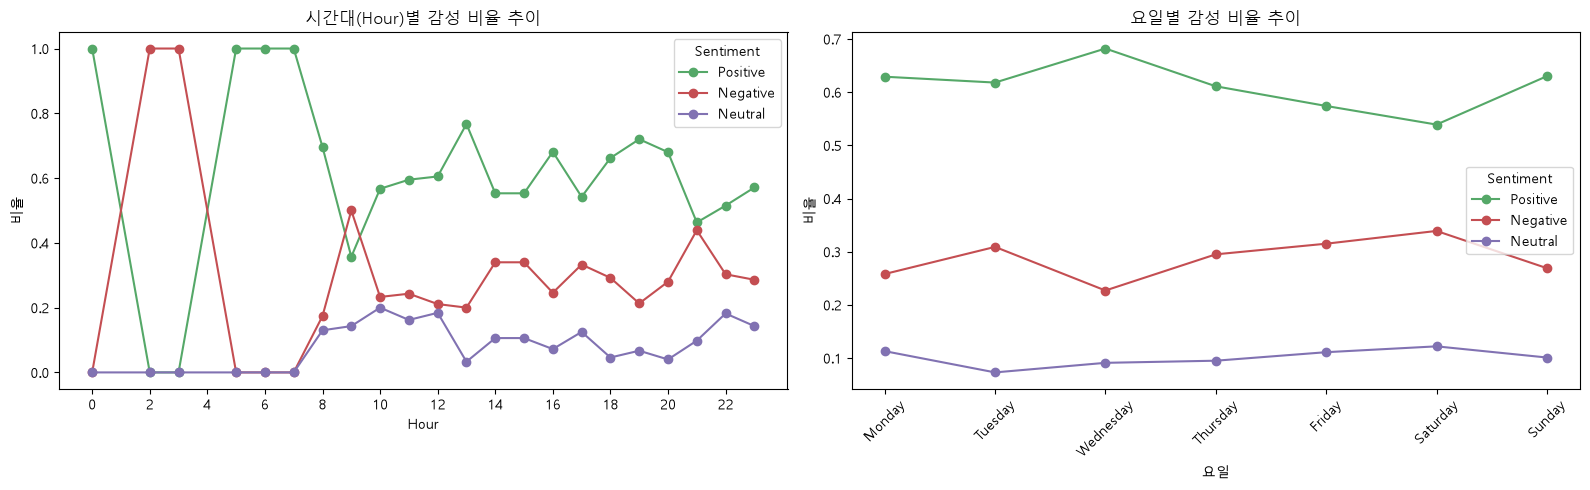

In [48]:
# ※ 실제 라벨(Sentiment_grouped) 기준 트렌드 확인 (전체 df 대상, EDA 6-6과 동일 방식)

# ── 1) Hour 별 감성 비율 (재확인) ─────────────────────────────────
hour_trend = pd.crosstab(
    df['Hour'], df['Sentiment_grouped'], normalize='index'
).sort_index().round(3)

print("=== 1) Hour 별 감성 비율 ===")
display(hour_trend)

# ── 2) 요일(day_of_week) 별 감성 비율 ─────────────────────────────
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

day_trend = pd.crosstab(
    df['day_of_week'], df['Sentiment_grouped'], normalize='index'
).reindex(weekday_order).round(3)

print("\n=== 2) 요일 별 감성 비율 ===")
display(day_trend)

# ── 3) 시각화 — Hour 트렌드 (Line) ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for label, color in zip(['Positive', 'Negative', 'Neutral'],
                          ['#55A868', '#C44E52', '#8172B2']):
    axes[0].plot(hour_trend.index, hour_trend[label],
                  marker='o', label=label, color=color)

axes[0].set_title('시간대(Hour)별 감성 비율 추이')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('비율')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(title='Sentiment')

# ── 4) 시각화 — 요일 트렌드 (Line) ────────────────────────────────
for label, color in zip(['Positive', 'Negative', 'Neutral'],
                          ['#55A868', '#C44E52', '#8172B2']):
    axes[1].plot(day_trend.index, day_trend[label],
                  marker='o', label=label, color=color)

axes[1].set_title('요일별 감성 비율 추이')
axes[1].set_xlabel('요일')
axes[1].set_ylabel('비율')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Sentiment')

plt.tight_layout()
plt.show()

##### 6-3. Positive/Negative 게시물 내 원본 세부 감정(Sentiment_original) 상위 분포

=== 1) Positive 게시물 내 세부 감정 상위 10개 (전체 446건 중) ===


,ratio
Sentiment_original,
Positive,0.101
Joy,0.099
Excitement,0.083
Contentment,0.043
Gratitude,0.040
Serenity,0.034
Happy,0.031
Awe,0.020
Hopeful,0.020



=== 2) Negative 게시물 내 세부 감정 상위 10개 (전체 212건 중) ===


,ratio
Sentiment_original,
Despair,0.052
Grief,0.042
Loneliness,0.042
Sad,0.042
Embarrassed,0.038
Elation,0.033
Euphoria,0.033
Frustration,0.028
Regret,0.028


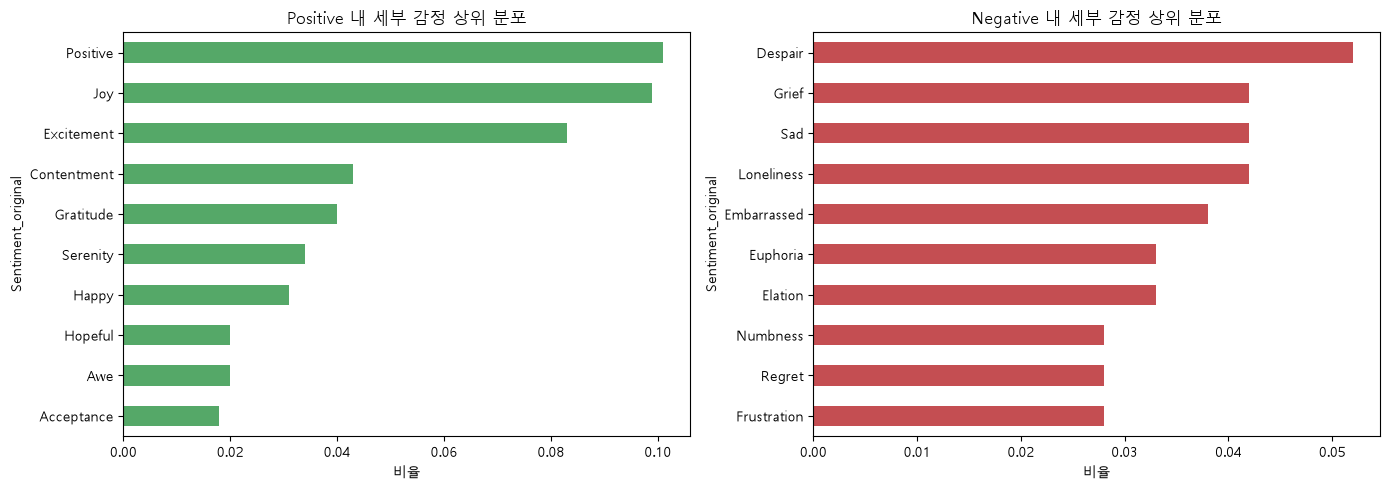

In [49]:
# ── 1) Positive로 분류된 게시물의 원본 세부 감정 Top-N ─────────────
TOP_N_EMOTIONS = 10

positive_posts = df[df['Sentiment_grouped'] == 'Positive']
positive_emotion_dist = (
    positive_posts['Sentiment_original']
    .value_counts(normalize=True)
    .head(TOP_N_EMOTIONS)
    .round(3)
)

print(f"=== 1) Positive 게시물 내 세부 감정 상위 {TOP_N_EMOTIONS}개 (전체 {len(positive_posts)}건 중) ===")
display(positive_emotion_dist.to_frame('ratio'))

# ── 2) Negative로 분류된 게시물의 원본 세부 감정 Top-N ─────────────
negative_posts = df[df['Sentiment_grouped'] == 'Negative']
negative_emotion_dist = (
    negative_posts['Sentiment_original']
    .value_counts(normalize=True)
    .head(TOP_N_EMOTIONS)
    .round(3)
)

print(f"\n=== 2) Negative 게시물 내 세부 감정 상위 {TOP_N_EMOTIONS}개 (전체 {len(negative_posts)}건 중) ===")
display(negative_emotion_dist.to_frame('ratio'))

# ── 3) 시각화 — Positive/Negative 세부 감정 분포 (Bar) ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

positive_emotion_dist.sort_values().plot(
    kind='barh', ax=axes[0], color='#55A868'
)
axes[0].set_title('Positive 내 세부 감정 상위 분포')
axes[0].set_xlabel('비율')

negative_emotion_dist.sort_values().plot(
    kind='barh', ax=axes[1], color='#C44E52'
)
axes[1].set_title('Negative 내 세부 감정 상위 분포')
axes[1].set_xlabel('비율')

plt.tight_layout()
plt.show()

### 7. 비교 모델

##### 7-1. 비교 모델 ① — Logistic Regression (SVM과 동일 피처: TF-IDF + 메타데이터)

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

# ── 1) 학습 (SVM과 동일한 X_train_scaled / X_test_scaled 사용 → 공정 비교) ──
logit_compare = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)
logit_compare.fit(X_train_scaled, y_train)
logit_compare_pred = logit_compare.predict(X_test_scaled)

# ── 2) 성능 확인 ──────────────────────────────────────────────────
print("=== 1) Logistic Regression (비교모델) ===")
print("Accuracy:", accuracy_score(y_test, logit_compare_pred))

logit_compare_report = pd.DataFrame(
    classification_report(y_test, logit_compare_pred, output_dict=True)
).T.round(3)
display(logit_compare_report)

logit_compare_cm = pd.DataFrame(
    confusion_matrix(y_test, logit_compare_pred, labels=logit_compare.classes_),
    index=[f'실제_{c}' for c in logit_compare.classes_],
    columns=[f'예측_{c}' for c in logit_compare.classes_]
)
display(logit_compare_cm)

=== 1) Logistic Regression (비교모델) ===
Accuracy: 0.8571428571428571


,precision,recall,f1-score,support
Negative,0.850,0.791,0.819,43.000
Neutral,0.889,0.533,0.667,15.000
Positive,0.857,0.944,0.898,89.000
accuracy,0.857,0.857,0.857,0.857
macro avg,0.865,0.756,0.795,147.000
weighted avg,0.858,0.857,0.852,147.000


,예측_Negative,예측_Neutral,예측_Positive
실제_Negative,34,0,9
실제_Neutral,2,8,5
실제_Positive,4,1,84


##### 7-2. 비교 모델 ② — BERT 계열 (DistilBERT Fine-tuning)

In [51]:
# ※ 최초 1회만 필요: !pip install transformers torch

import torch
from torch.utils.data import Dataset
from sklearn.preprocessing import LabelEncoder
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                            TrainingArguments, Trainer)
from sklearn.metrics import accuracy_score, f1_score

In [52]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("=== 1) 사용 디바이스 확인 ===")
print(device)

# ── 1) SVM/Logistic과 동일한 Train/Test 인덱스로 텍스트 분할 (공정 비교) ──
# BERT는 자체 서브워드 토크나이저를 사용하므로 TF-IDF용 전처리(Text_clean) 대신
# 원본에 가까운 Text(소문자화만 적용) 사용
texts_train = df.loc[y_train.index, 'Text'].str.lower().tolist()
texts_test = df.loc[y_test.index, 'Text'].str.lower().tolist()

# ── 2) 라벨 인코딩 (Sentiment_grouped: Positive/Negative/Neutral → 0/1/2) ──
label_encoder = LabelEncoder()
labels_train = label_encoder.fit_transform(y_train)
labels_test = label_encoder.transform(y_test)

print("\n=== 2) 라벨 인코딩 매핑 ===")
display(pd.DataFrame({
    'label': label_encoder.classes_,
    'encoded': range(len(label_encoder.classes_))
}))

# ── 3) 토크나이저 및 Dataset 클래스 정의 ───────────────────────────
MODEL_NAME = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(texts_train, truncation=True, padding=True, max_length=64)
test_encodings = tokenizer(texts_test, truncation=True, padding=True, max_length=64)

class SentimentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = SentimentDataset(train_encodings, labels_train)
test_dataset = SentimentDataset(test_encodings, labels_test)

# ── 4) 모델 로드 (3-class 분류) ────────────────────────────────────
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(label_encoder.classes_)
).to(device)

# ── 5) 평가 지표 함수 정의 ──────────────────────────────────────────
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'macro_f1': f1_score(labels, preds, average='macro'),
        'weighted_f1': f1_score(labels, preds, average='weighted')
    }

# ── 6) 학습 설정 (소규모 데이터셋 → 적은 epoch, 작은 batch size) ──────
training_args = TrainingArguments(
    output_dir='./bert_results',
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    eval_strategy='epoch',
    logging_strategy='epoch',
    save_strategy='no',
    report_to='none'
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

# ── 7) Fine-tuning 실행 ────────────────────────────────────────────
print("\n=== 3) DistilBERT Fine-tuning 진행 ===")
trainer.train()

# ── 8) Test셋 최종 예측 및 성능 확인 ────────────────────────────────
bert_output = trainer.predict(test_dataset)
bert_pred_encoded = bert_output.predictions.argmax(-1)
bert_pred = label_encoder.inverse_transform(bert_pred_encoded)

print("\n=== 4) DistilBERT (비교모델) Test 성능 ===")
print("Accuracy:", accuracy_score(y_test, bert_pred))

bert_report = pd.DataFrame(
    classification_report(y_test, bert_pred, output_dict=True)
).T.round(3)
display(bert_report)

bert_cm = pd.DataFrame(
    confusion_matrix(y_test, bert_pred, labels=label_encoder.classes_),
    index=[f'실제_{c}' for c in label_encoder.classes_],
    columns=[f'예측_{c}' for c in label_encoder.classes_]
)
display(bert_cm)

=== 1) 사용 디바이스 확인 ===
cpu

=== 2) 라벨 인코딩 매핑 ===


,label,encoded
0,Negative,0
1,Neutral,1
2,Positive,2


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 527.93it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== 3) DistilBERT Fine-tuning 진행 ===


c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


...

c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



=== 4) DistilBERT (비교모델) Test 성능 ===
Accuracy: 0.8435374149659864


c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\82102\.virtualenvs\study-k17Ljfr1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

,precision,recall,f1-score,support
Negative,0.776,0.884,0.826,43.000
Neutral,0.000,0.000,0.000,15.000
Positive,0.878,0.966,0.920,89.000
accuracy,0.844,0.844,0.844,0.844
macro avg,0.551,0.617,0.582,147.000
weighted avg,0.758,0.844,0.799,147.000


,예측_Negative,예측_Neutral,예측_Positive
실제_Negative,38,0,5
실제_Neutral,8,0,7
실제_Positive,3,0,86


##### 7-3. 3개 모델 최종 성능 비교 (SVM vs Logistic Regression vs BERT)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

=== 1) 3개 모델 최종 성능 비교 ===


,Accuracy,Macro F1,Weighted F1
SVM (linear),0.857,0.797,0.852
Logistic Regression,0.857,0.795,0.852
BERT (DistilBERT),0.844,0.582,0.799


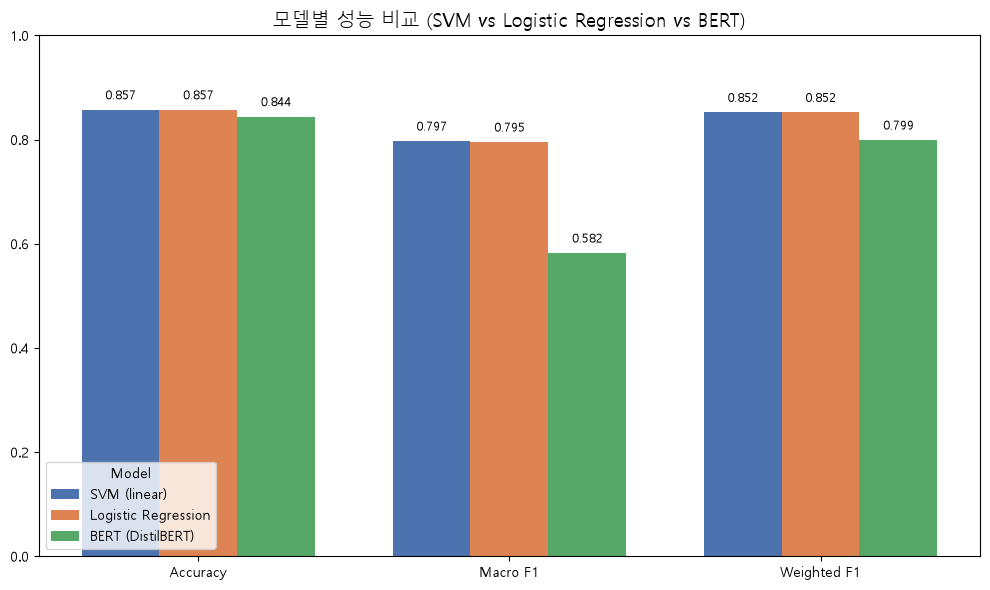


=== 2) Macro F1 기준 최고 성능 모델: SVM (linear) ===


In [54]:
# ── 1) SVM 최종 예측 재확인 (9-4에서 선택된 최종 커널 모델 사용) ──────
y_pred_svm_final = final_svm_model.predict(X_test_scaled)

# ── 2) 모델별 성능 집계 ────────────────────────────────────────────
comparison_models = pd.DataFrame({
    'Accuracy': [
        accuracy_score(y_test, y_pred_svm_final),
        accuracy_score(y_test, logit_compare_pred),
        accuracy_score(y_test, bert_pred)
    ],
    'Macro F1': [
        f1_score(y_test, y_pred_svm_final, average='macro'),
        f1_score(y_test, logit_compare_pred, average='macro'),
        f1_score(y_test, bert_pred, average='macro')
    ],
    'Weighted F1': [
        f1_score(y_test, y_pred_svm_final, average='weighted'),
        f1_score(y_test, logit_compare_pred, average='weighted'),
        f1_score(y_test, bert_pred, average='weighted')
    ]
}, index=[f'SVM ({final_kernel})', 'Logistic Regression', 'BERT (DistilBERT)']).round(3)

print("=== 1) 3개 모델 최종 성능 비교 ===")
display(comparison_models)

# ── 3) 시각화 — 지표별 그룹 막대그래프 (PCA 전/후 비교와 동일한 방식) ──
metrics = ['Accuracy', 'Macro F1', 'Weighted F1']
model_names = comparison_models.index.tolist()
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(metrics))
width = 0.25

for i, model_name in enumerate(model_names):
    values = comparison_models.loc[model_name, metrics].values
    bars = ax.bar(x + (i - 1) * width, values, width, label=model_name, color=colors[i])
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f'{v:.3f}',
                 ha='center', fontsize=9)

ax.set_title('모델별 성능 비교 (SVM vs Logistic Regression vs BERT)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend(title='Model')

plt.tight_layout()
plt.show()

# ── 4) 최고 성능 모델 확인 ─────────────────────────────────────────
best_model_name = comparison_models['Macro F1'].idxmax()
print(f"\n=== 2) Macro F1 기준 최고 성능 모델: {best_model_name} ===")